In [1]:
import numpy as np
import pandas as pd
from sklearn import metrics
# Replaced load_boston with fetch_california_housing
from sklearn.datasets import fetch_california_housing 
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeRegressor

In [76]:
housing = fetch_california_housing()

In [77]:
df = pd.DataFrame(housing.data, columns=housing.feature_names)

In [78]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [79]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [80]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [81]:
rt  = DecisionTreeRegressor(max_depth=7,min_samples_leaf=100,splitter='best')

In [82]:
rt.fit(X_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,100
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [83]:
y_pred = rt.predict(X_test)

In [84]:
r2_score(y_test,y_pred)

0.6734631762294359

In [85]:
from sklearn.tree import plot_tree

[Text(0.6096875, 0.9375, 'x[1] <= 5.971\nsquared_error = 3.626\nsamples = 16512\nvalue = 3.881'),
 Text(0.340625, 0.8125, 'x[1] <= 4.905\nsquared_error = 1.478\nsamples = 12013\nvalue = 3.232'),
 Text(0.47515625000000006, 0.875, 'True  '),
 Text(0.1575, 0.6875, 'x[1] <= 4.101\nsquared_error = 0.993\nsamples = 6401\nvalue = 2.763'),
 Text(0.06, 0.5625, 'x[1] <= 3.062\nsquared_error = 0.738\nsamples = 2630\nvalue = 2.423'),
 Text(0.02, 0.4375, 'x[2] <= 0.988\nsquared_error = 0.708\nsamples = 399\nvalue = 1.93'),
 Text(0.01, 0.3125, 'squared_error = 1.393\nsamples = 102\nvalue = 2.351'),
 Text(0.03, 0.3125, 'x[1] <= 2.556\nsquared_error = 0.391\nsamples = 297\nvalue = 1.785'),
 Text(0.02, 0.1875, 'squared_error = 0.282\nsamples = 114\nvalue = 1.611'),
 Text(0.04, 0.1875, 'squared_error = 0.429\nsamples = 183\nvalue = 1.893'),
 Text(0.1, 0.4375, 'x[4] <= 2.094\nsquared_error = 0.692\nsamples = 2231\nvalue = 2.511'),
 Text(0.07, 0.3125, 'x[1] <= 3.501\nsquared_error = 0.915\nsamples = 521\n

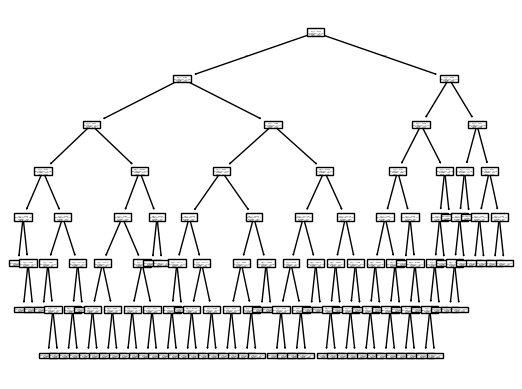

In [86]:
plot_tree(rt)

In [69]:
import seaborn as sns

<Axes: xlabel='Longitude', ylabel='Latitude'>

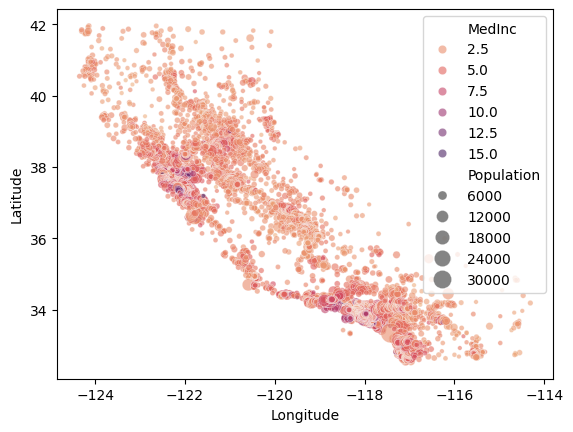

In [89]:
sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue="MedInc",  # Color points by house value
    palette="flare",  # Smooth color gradient
    size="Population",  # Size points by population
    sizes=(10, 200),  # Min and max size of points
    alpha=0.6,  # Make points slightly transparent to see overlap
)

In [90]:
from sklearn.linear_model import LinearRegression

In [91]:
lr = LinearRegression()

In [92]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [93]:
y_pred = lr.predict(X_test)

In [96]:
from sklearn.metrics import accuracy_score

In [98]:
from sklearn.model_selection import GridSearchCV

# Define a search space around your current settings
param_grid = {
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [10, 20, 50, 100]
}

grid = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5, scoring='r2')
grid.fit(X_train, y_train)

print(f"Optimized Tree R2 Score: {grid.best_score_:.4f}")
print(f"Best parameters: {grid.best_params_}")

Optimized Tree R2 Score: 0.7013
Best parameters: {'max_depth': 20, 'min_samples_leaf': 20}
